In [1]:
import json
import logging
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
BASELINE_MODELS_DIR = PROJECT_ROOT / "models" / "supervised" / "baseline_models"
IMBALANCE_MODELS_DIR = PROJECT_ROOT / "models" / "supervised" / "class_imbalance_models"
ANOMALY_MODELS_DIR = PROJECT_ROOT / "models" / "anomaly" / "baseline_anomaly_models"

RANDOM_SEED = 42
FEATURE_CONFIGURATION = "log_amount_and_time_hours"
DEFAULT_THRESHOLD = 0.5

SUPERVISED_VS_ANOMALY_COMPARISON_PATH = (
    REPORTS_DIR / "supervised_vs_anomaly_comparison.csv"
)
MODEL_AGREEMENT_PATH = REPORTS_DIR / "model_agreement_analysis.csv"
MODEL_EVALUATION_REPORT_PATH = REPORTS_DIR / "model_evaluation_report.md"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
)

logger = logging.getLogger(__name__)

logger.info("Project root: %s", PROJECT_ROOT)

2026-11-01 11:49:33,121 | INFO | Project root: c:\Users\use\Desktop\Credit Card Fraud Detection


In [3]:
def load_split(
    feature_path: Path,
    target_path: Path,
) -> tuple[pd.DataFrame, pd.Series]:
    """Load a feature matrix and target vector from Parquet files."""
    if not feature_path.exists():
        raise FileNotFoundError(f"Feature file not found: {feature_path}")

    if not target_path.exists():
        raise FileNotFoundError(f"Target file not found: {target_path}")

    features = pd.read_parquet(feature_path)
    target_dataframe = pd.read_parquet(target_path)

    if features.empty or target_dataframe.empty:
        raise ValueError("Loaded split is empty.")

    target_column = target_dataframe.columns[0]
    target = target_dataframe[target_column]

    if len(features) != len(target):
        raise ValueError("Feature and target row counts do not match.")

    return features, target


def add_log_amount_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add a zero-safe logarithmic transformation of Amount."""
    if "Amount" not in features.columns:
        raise ValueError("Required column 'Amount' is missing.")

    if (features["Amount"] < 0).any():
        raise ValueError("Negative Amount values found; log1p is not appropriate.")

    transformed = features.copy()
    transformed["Amount_log1p"] = np.log1p(transformed["Amount"])
    return transformed


def add_elapsed_time_hours_feature(features: pd.DataFrame) -> pd.DataFrame:
    """Add elapsed transaction time expressed in hours."""
    if "Time" not in features.columns:
        raise ValueError("Required column 'Time' is missing.")

    transformed = features.copy()
    transformed["Time_hours"] = transformed["Time"] / 3600.0
    return transformed


X_validation, y_validation = load_split(
    feature_path=DATA_PROCESSED_DIR / "validation" / "X_validation.parquet",
    target_path=DATA_PROCESSED_DIR / "validation" / "y_validation.parquet",
)

X_validation_engineered = add_elapsed_time_hours_feature(
    add_log_amount_feature(X_validation)
)

if "Class" in X_validation_engineered.columns:
    raise ValueError("Target leakage detected in validation features.")

logger.info("Validation features: %s", X_validation_engineered.shape)
logger.info("Validation fraud count: %s", int(y_validation.sum()))

2026-11-01 11:49:33,334 | INFO | Validation features: (42559, 32)
2026-11-01 11:49:33,338 | INFO | Validation fraud count: 71


In [4]:
SUPERVISED_MODELS = {
    "Random Forest | Class weighting": (
        IMBALANCE_MODELS_DIR
        / "random_forest_class_weighting"
        / "model.joblib"
    ),
    "Random Forest | SMOTE": (
        IMBALANCE_MODELS_DIR
        / "random_forest_smote"
        / "model.joblib"
    ),
    "Logistic Regression | SMOTE": (
        IMBALANCE_MODELS_DIR
        / "logistic_regression_smote"
        / "model.joblib"
    ),
}

ANOMALY_MODELS = {
    "Isolation Forest | Baseline": (
        ANOMALY_MODELS_DIR
        / "isolation_forest_baseline"
        / "model.joblib"
    ),
    "Local Outlier Factor | Baseline": (
        ANOMALY_MODELS_DIR
        / "local_outlier_factor_baseline"
        / "model.joblib"
    ),
}

ALL_MODEL_PATHS = {
    **SUPERVISED_MODELS,
    **ANOMALY_MODELS,
}

for model_name, model_path in ALL_MODEL_PATHS.items():
    if not model_path.exists():
        raise FileNotFoundError(f"Model artifact not found for {model_name}: {model_path}")

logger.info("Prepared %s models for validation comparison.", len(ALL_MODEL_PATHS))

2026-11-01 11:49:51,303 | INFO | Prepared 5 models for validation comparison.


In [5]:
def generate_model_outputs(
    model_name: str,
    model_path: Path,
    X_validation: pd.DataFrame,
) -> tuple[np.ndarray, np.ndarray]:
    """Generate validation scores and binary flags for one model."""
    pipeline = joblib.load(model_path)

    if model_name in SUPERVISED_MODELS:
        scores = pipeline.predict_proba(X_validation)[:, 1]
        predictions = (scores >= DEFAULT_THRESHOLD).astype(int)
    else:
        raw_scores = pipeline.decision_function(X_validation)

        # Reverse the sign so higher values consistently mean more anomalous.
        scores = -raw_scores
        predictions = pipeline.predict(X_validation)
        predictions = np.where(predictions == -1, 1, 0)

    return scores, predictions


validation_scores = {}
validation_predictions = {}

for model_name, model_path in ALL_MODEL_PATHS.items():
    logger.info("Generating validation outputs for: %s", model_name)

    scores, predictions = generate_model_outputs(
        model_name=model_name,
        model_path=model_path,
        X_validation=X_validation_engineered,
    )

    validation_scores[model_name] = scores
    validation_predictions[model_name] = predictions

logger.info("Validation outputs generated for all models.")

2026-11-01 11:49:58,485 | INFO | Generating validation outputs for: Random Forest | Class weighting
2026-11-01 11:50:00,003 | INFO | Generating validation outputs for: Random Forest | SMOTE
2026-11-01 11:50:02,857 | INFO | Generating validation outputs for: Logistic Regression | SMOTE
2026-11-01 11:50:02,985 | INFO | Generating validation outputs for: Isolation Forest | Baseline
2026-11-01 11:50:06,823 | INFO | Generating validation outputs for: Local Outlier Factor | Baseline
2026-11-01 11:51:18,585 | INFO | Validation outputs generated for all models.


In [6]:
def calculate_validation_metrics(
    model_name: str,
    model_type: str,
    y_true: pd.Series,
    scores: np.ndarray,
    predictions: np.ndarray,
) -> dict:
    """Calculate validation metrics for one model."""
    confusion = confusion_matrix(y_true, predictions, labels=[0, 1])
    true_negative, false_positive, false_negative, true_positive = confusion.ravel()

    false_positive_rate = (
        false_positive / (false_positive + true_negative)
        if (false_positive + true_negative) > 0
        else 0.0
    )

    return {
        "model_name": model_name,
        "model_type": model_type,
        "decision_rule": (
            f"Probability >= {DEFAULT_THRESHOLD}"
            if model_type == "Supervised"
            else "Fitted contamination-based anomaly rule"
        ),
        "precision": float(
            precision_score(y_true, predictions, zero_division=0)
        ),
        "recall": float(
            recall_score(y_true, predictions, zero_division=0)
        ),
        "f1_score": float(
            f1_score(y_true, predictions, zero_division=0)
        ),
        "pr_auc": float(average_precision_score(y_true, scores)),
        "roc_auc": float(roc_auc_score(y_true, scores)),
        "false_positive_rate": float(false_positive_rate),
        "true_positives": int(true_positive),
        "false_positives": int(false_positive),
        "true_negatives": int(true_negative),
        "false_negatives": int(false_negative),
        "transactions_flagged": int(true_positive + false_positive),
    }


comparison_results = []

for model_name in ALL_MODEL_PATHS:
    model_type = (
        "Supervised"
        if model_name in SUPERVISED_MODELS
        else "Unsupervised anomaly detection"
    )

    comparison_results.append(
        calculate_validation_metrics(
            model_name=model_name,
            model_type=model_type,
            y_true=y_validation,
            scores=validation_scores[model_name],
            predictions=validation_predictions[model_name],
        )
    )

comparison_results_dataframe = pd.DataFrame(comparison_results)

comparison_results_dataframe[
    [
        "model_name",
        "model_type",
        "decision_rule",
        "precision",
        "recall",
        "f1_score",
        "pr_auc",
        "roc_auc",
        "false_positive_rate",
        "transactions_flagged",
        "false_positives",
        "false_negatives",
    ]
]

,model_name,model_type,decision_rule,precision,recall,f1_score,pr_auc,roc_auc,false_positive_rate,transactions_flagged,false_positives,false_negatives
0,Random Forest | Class weighting,Supervised,Probability >= 0.5,0.963636,0.746479,0.841270,0.849424,0.945599,0.000047,55,2,18
1,Random Forest | SMOTE,Supervised,Probability >= 0.5,0.888889,0.788732,0.835821,0.840671,0.961678,0.000165,63,7,15
2,Logistic Regression | SMOTE,Supervised,Probability >= 0.5,0.047800,0.887324,0.090713,0.709086,0.969187,0.029538,1318,1255,8
3,Isolation Forest | Baseline,Unsupervised anomaly detection,Fitted contamination-based anomaly rule,0.222222,0.112676,0.149533,0.079585,0.933193,0.000659,36,28,63
4,Local Outlier Factor | Baseline,Unsupervised anomaly detection,Fitted contamination-based anomaly rule,0.000000,0.000000,0.000000,0.002650,0.514945,0.001106,47,47,71


In [7]:
comparison_results_dataframe.to_csv(
    SUPERVISED_VS_ANOMALY_COMPARISON_PATH,
    index=False,
)

logger.info(
    "Supervised-versus-anomaly comparison saved to: %s",
    SUPERVISED_VS_ANOMALY_COMPARISON_PATH,
)

2026-11-01 11:51:36,263 | INFO | Supervised-versus-anomaly comparison saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\supervised_vs_anomaly_comparison.csv


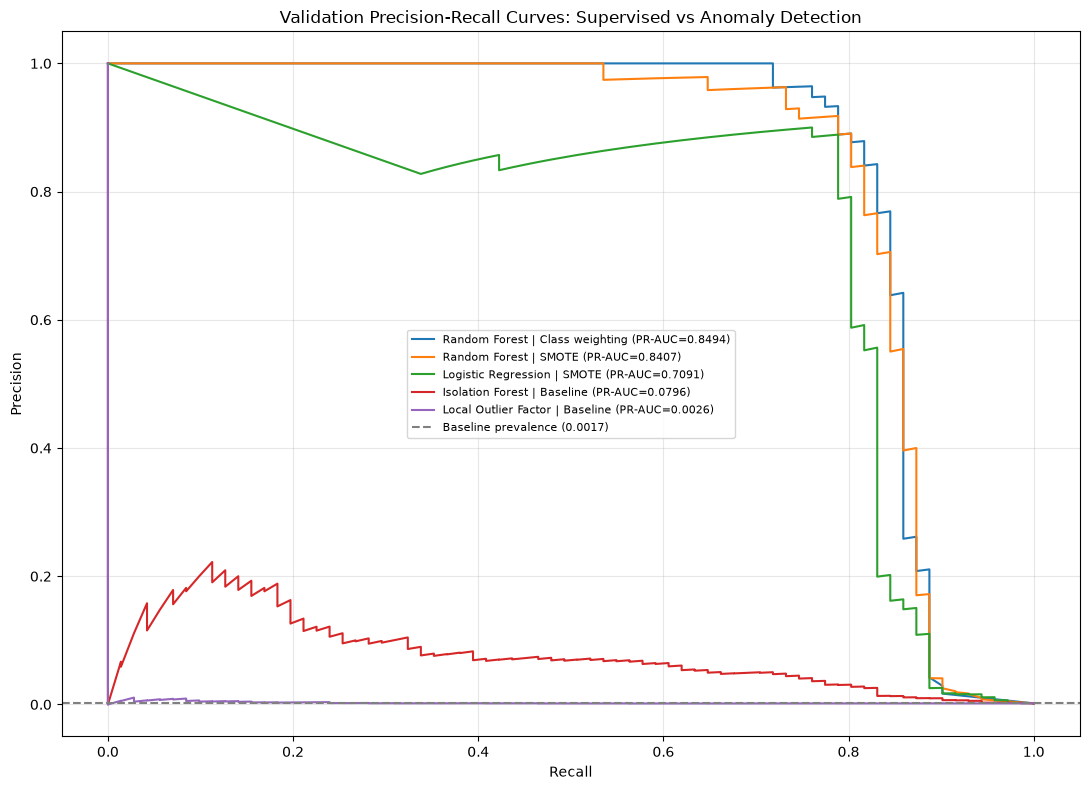

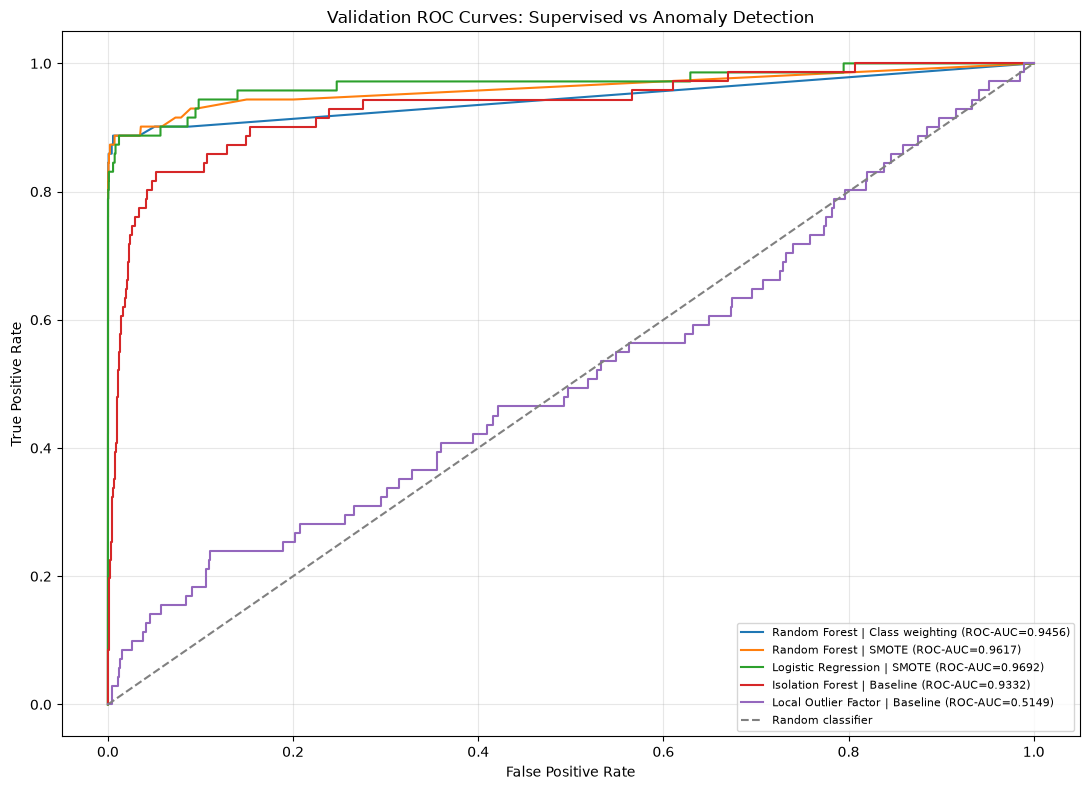

2026-11-01 11:51:50,573 | INFO | Model comparison PR and ROC curves generated.


In [8]:
def plot_model_precision_recall_curves(
    y_true: pd.Series,
    scores_by_model: dict[str, np.ndarray],
    output_path: Path,
) -> None:
    """Plot validation precision-recall curves for all compared models."""
    plt.figure(figsize=(11, 8))

    for model_name, scores in scores_by_model.items():
        precision_values, recall_values, _ = precision_recall_curve(
            y_true,
            scores,
        )
        pr_auc = average_precision_score(y_true, scores)

        plt.plot(
            recall_values,
            precision_values,
            label=f"{model_name} (PR-AUC={pr_auc:.4f})",
        )

    fraud_prevalence = y_true.mean()
    plt.axhline(
        fraud_prevalence,
        color="gray",
        linestyle="--",
        label=f"Baseline prevalence ({fraud_prevalence:.4f})",
    )

    plt.title("Validation Precision-Recall Curves: Supervised vs Anomaly Detection")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend(fontsize=8)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


def plot_model_roc_curves(
    y_true: pd.Series,
    scores_by_model: dict[str, np.ndarray],
    output_path: Path,
) -> None:
    """Plot validation ROC curves for all compared models."""
    plt.figure(figsize=(11, 8))

    for model_name, scores in scores_by_model.items():
        false_positive_rate, true_positive_rate, _ = roc_curve(
            y_true,
            scores,
        )
        roc_auc = roc_auc_score(y_true, scores)

        plt.plot(
            false_positive_rate,
            true_positive_rate,
            label=f"{model_name} (ROC-AUC={roc_auc:.4f})",
        )

    plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random classifier")

    plt.title("Validation ROC Curves: Supervised vs Anomaly Detection")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(fontsize=8)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


model_pr_figure_path = (
    FIGURES_DIR / "supervised_vs_anomaly_precision_recall_curves.png"
)
model_roc_figure_path = (
    FIGURES_DIR / "supervised_vs_anomaly_roc_curves.png"
)

plot_model_precision_recall_curves(
    y_true=y_validation,
    scores_by_model=validation_scores,
    output_path=model_pr_figure_path,
)

plot_model_roc_curves(
    y_true=y_validation,
    scores_by_model=validation_scores,
    output_path=model_roc_figure_path,
)

logger.info("Model comparison PR and ROC curves generated.")

In [9]:
PRIMARY_SUPERVISED_MODEL = "Random Forest | Class weighting"
PRIMARY_ANOMALY_MODEL = "Isolation Forest | Baseline"


def analyze_model_agreement(
    y_true: pd.Series,
    supervised_predictions: np.ndarray,
    anomaly_predictions: np.ndarray,
    X_validation: pd.DataFrame,
) -> pd.DataFrame:
    """Categorize validation transactions by supervised and anomaly-detector agreement."""
    agreement_categories = []

    for index in range(len(y_true)):
        supervised_flag = int(supervised_predictions[index])
        anomaly_flag = int(anomaly_predictions[index])
        actual_label = int(y_true.iloc[index])

        if supervised_flag == 1 and anomaly_flag == 1:
            category = "A: Both models flag"
        elif supervised_flag == 1 and anomaly_flag == 0:
            category = "B: Supervised model only"
        elif supervised_flag == 0 and anomaly_flag == 1:
            category = "C: Anomaly detector only"
        else:
            category = "D: Neither model flags"

        agreement_categories.append(
            {
                "agreement_category": category,
                "actual_class": actual_label,
                "amount": float(X_validation.iloc[index]["Amount"]),
            }
        )

    return pd.DataFrame(agreement_categories)


agreement_dataframe = analyze_model_agreement(
    y_true=y_validation,
    supervised_predictions=validation_predictions[PRIMARY_SUPERVISED_MODEL],
    anomaly_predictions=validation_predictions[PRIMARY_ANOMALY_MODEL],
    X_validation=X_validation_engineered,
)

agreement_summary = (
    agreement_dataframe
    .groupby("agreement_category")
    .agg(
        transaction_count=("actual_class", "size"),
        fraud_count=("actual_class", "sum"),
        median_amount=("amount", "median"),
        minimum_amount=("amount", "min"),
        maximum_amount=("amount", "max"),
    )
    .reset_index()
    .sort_values("agreement_category")
)

agreement_summary["fraud_rate"] = (
    agreement_summary["fraud_count"] / agreement_summary["transaction_count"]
)

agreement_summary.to_csv(MODEL_AGREEMENT_PATH, index=False)

agreement_summary

,agreement_category,transaction_count,fraud_count,median_amount,minimum_amount,maximum_amount,fraud_rate
0,A: Both models flag,8,8,68.84,1.00,106.55,1.000000
1,B: Supervised model only,47,45,24.90,0.00,1389.56,0.957447
2,C: Anomaly detector only,28,0,1557.55,1.98,25691.16,0.000000
3,D: Neither model flags,42476,18,21.02,0.00,4692.65,0.000424


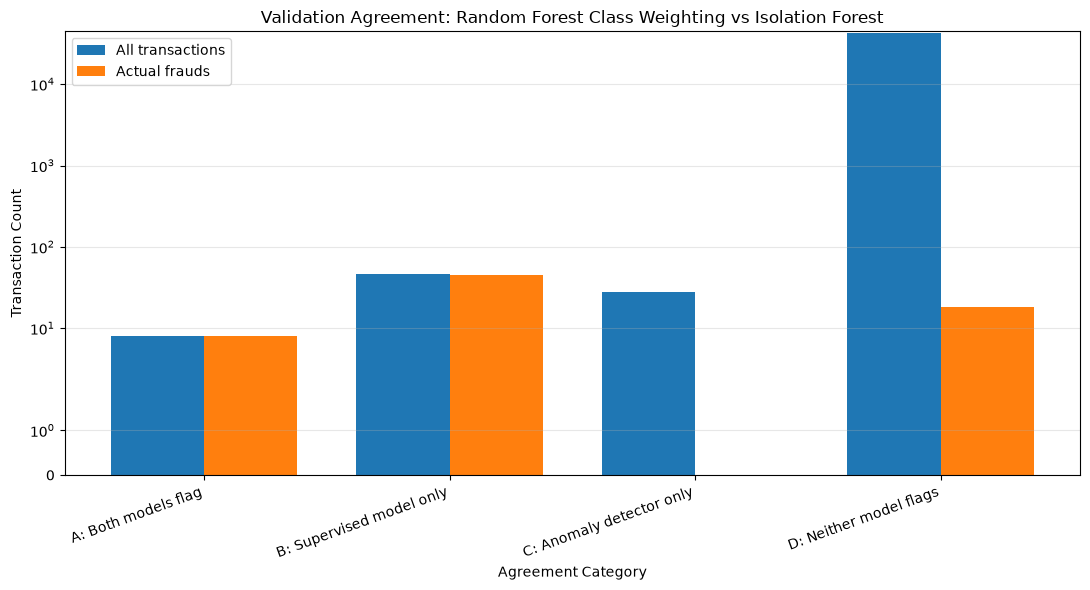

2026-11-01 11:52:16,987 | INFO | Model-agreement figure saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\figures\supervised_vs_anomaly_agreement.png


In [10]:
def plot_model_agreement(
    agreement_summary: pd.DataFrame,
    output_path: Path,
) -> None:
    """Plot transaction and fraud counts by model-agreement category."""
    plt.figure(figsize=(11, 6))

    x_positions = np.arange(len(agreement_summary))
    bar_width = 0.38

    plt.bar(
        x_positions - bar_width / 2,
        agreement_summary["transaction_count"],
        width=bar_width,
        label="All transactions",
    )

    plt.bar(
        x_positions + bar_width / 2,
        agreement_summary["fraud_count"],
        width=bar_width,
        label="Actual frauds",
    )

    plt.xticks(
        x_positions,
        agreement_summary["agreement_category"],
        rotation=20,
        ha="right",
    )
    plt.title(
        "Validation Agreement: Random Forest Class Weighting vs Isolation Forest"
    )
    plt.xlabel("Agreement Category")
    plt.ylabel("Transaction Count")
    plt.yscale("symlog")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


model_agreement_figure_path = (
    FIGURES_DIR / "supervised_vs_anomaly_agreement.png"
)

plot_model_agreement(
    agreement_summary=agreement_summary,
    output_path=model_agreement_figure_path,
)

logger.info(
    "Model-agreement figure saved to: %s",
    model_agreement_figure_path,
)

In [11]:
def write_model_evaluation_report(
    comparison_results: pd.DataFrame,
    agreement_summary: pd.DataFrame,
    report_path: Path,
) -> None:
    """Write the supervised-versus-anomaly evaluation report."""
    report_lines = [
        "# Supervised vs Anomaly Detection Evaluation",
        "",
        "## Scope",
        "",
        f"- Feature configuration: `{FEATURE_CONFIGURATION}`",
        "- Evaluation dataset: Validation set",
        f"- Supervised decision threshold: {DEFAULT_THRESHOLD}",
        "- Anomaly decision rule: Fitted contamination-based rule",
        "- Test set: Not used",
        "",
        "## Validation Results",
        "",
    ]

    for _, row in comparison_results.iterrows():
        report_lines.extend(
            [
                f"### {row['model_name']}",
                "",
                f"- Model type: {row['model_type']}",
                f"- Decision rule: {row['decision_rule']}",
                f"- Precision: {row['precision']:.4f}",
                f"- Recall: {row['recall']:.4f}",
                f"- F1-score: {row['f1_score']:.4f}",
                f"- PR-AUC: {row['pr_auc']:.4f}",
                f"- ROC-AUC: {row['roc_auc']:.4f}",
                f"- False-positive rate: {row['false_positive_rate']:.6f}",
                f"- Transactions flagged: {row['transactions_flagged']:,}",
                f"- True positives: {row['true_positives']}",
                f"- False positives: {row['false_positives']:,}",
                f"- False negatives: {row['false_negatives']}",
                "",
            ]
        )

    report_lines.extend(
        [
            "## Agreement Analysis",
            "",
            "Primary supervised model: Random Forest | Class weighting",
            "",
            "Primary anomaly detector: Isolation Forest | Baseline",
            "",
        ]
    )

    for _, row in agreement_summary.iterrows():
        report_lines.extend(
            [
                f"### {row['agreement_category']}",
                "",
                f"- Transactions: {row['transaction_count']:,}",
                f"- Actual frauds: {row['fraud_count']:,}",
                f"- Fraud rate: {row['fraud_rate']:.4f}",
                f"- Median amount: {row['median_amount']:.2f}",
                "",
            ]
        )

    report_lines.extend(
        [
            "## Interpretation",
            "",
            "- Supervised and anomaly-detection metrics are not directly interchangeable because their decision rules differ.",
            "- PR-AUC is the primary ranking metric because fraud is extremely rare.",
            "- Anomaly scores are not fraud probabilities.",
            "- Agreement between models does not prove that a transaction is fraudulent.",
            "- The strongest supervised candidate remains Random Forest | Class weighting based on validation PR-AUC.",
            "- The untouched test set remains reserved for final evaluation.",
        ]
    )

    report_path.write_text("\n".join(report_lines), encoding="utf-8")


write_model_evaluation_report(
    comparison_results=comparison_results_dataframe,
    agreement_summary=agreement_summary,
    report_path=MODEL_EVALUATION_REPORT_PATH,
)

logger.info(
    "Model-evaluation report saved to: %s",
    MODEL_EVALUATION_REPORT_PATH,
)

2026-11-01 11:52:23,097 | INFO | Model-evaluation report saved to: c:\Users\use\Desktop\Credit Card Fraud Detection\reports\model_evaluation_report.md


In [12]:
required_evaluation_artifacts = [
    SUPERVISED_VS_ANOMALY_COMPARISON_PATH,
    MODEL_AGREEMENT_PATH,
    MODEL_EVALUATION_REPORT_PATH,
    model_pr_figure_path,
    model_roc_figure_path,
    model_agreement_figure_path,
]

missing_artifacts = [
    path for path in required_evaluation_artifacts if not path.exists()
]

if missing_artifacts:
    raise FileNotFoundError(
        f"Missing model-evaluation artifacts: {[str(path) for path in missing_artifacts]}"
    )

logger.info("All required model-evaluation artifacts were generated successfully.")
print("Phase 6 model evaluation completed successfully.")

2026-11-01 11:52:36,229 | INFO | All required model-evaluation artifacts were generated successfully.


Phase 6 model evaluation completed successfully.
